# Graph — Deteksi Simpul Anomali (feature graf + model anomali)
**Kapan dipakai:** ada jaringan (transaksi, sosial, sitasi, telekomunikasi) dan diminta mencari
simpul yang "aneh" (penipu, spammer, bot, kelompok palsu) tanpa label.

**Idenya:** tiap simpul diberi feature dari struktur graf (derajat, clustering, PageRank,
derajat tetangga, jumlah segitiga, core number). Model anomali menandai simpul yang polanya
menyimpang dari mayoritas.

**Langkah:**
1. Baca graf (data demo: sisipkan anomali buatan supaya ada kunci jawaban).
2. Hitung feature tiap simpul, beri skor anomali.
3. Simpan skor. Cek dengan kunci jawaban di sel terakhir (hanya data demo).

**Data demo:** graf sitasi Cora (2.708 simpul) + 10 kelompok "klik" (10 simpul saling
terhubung semua) + 20 "spammer" (satu simpul menyambung ke 40 simpul acak).

In [1]:
import matplotlib.pyplot as plt
import networkx as nx
import numpy as np
import pandas as pd
from pyod.models.ecod import ECOD
from pyod.models.hbos import HBOS
from pyod.models.iforest import IForest
from pyod.models.knn import KNN
from pyod.models.lof import LOF
from sklearn.metrics import average_precision_score, roc_auc_score
from sklearn.preprocessing import StandardScaler

## Konfigurasi

In [2]:
DATA_FOLDER = "../../../data_latihan/graph/cora"   # GANTI saat lomba
NODES_CSV = f"{DATA_FOLDER}/nodes.csv"
EDGES_CSV = f"{DATA_FOLDER}/edges.csv"

NODE_ID_COL = "id"
SOURCE_COL = "source"
TARGET_COL = "target"
N_CLIQUES = 10            # hanya demo: banyak kelompok klik
CLIQUE_SIZE = 10          # hanya demo: simpul per klik
N_SPAMMERS = 20           # hanya demo: banyak spammer
SPAMMER_LINKS = 40        # hanya demo: sambungan tiap spammer
ANOMALY_FRACTION = 0.045  # perkiraan porsi anomali (dipakai sebagian model)
SEED = 42

## Baca data

In [3]:
nodes = pd.read_csv(NODES_CSV, usecols=[NODE_ID_COL])
edges = pd.read_csv(EDGES_CSV)
graph = nx.Graph()
graph.add_nodes_from(nodes[NODE_ID_COL])
graph.add_edges_from(zip(edges[SOURCE_COL], edges[TARGET_COL]))
graph.remove_edges_from(nx.selfloop_edges(graph))     # buang sisi dari simpul ke dirinya sendiri
all_nodes = list(graph.nodes)
print(graph.number_of_nodes(), "simpul,", graph.number_of_edges(), "sisi")

2708 simpul, 5278 sisi


## Sisipkan anomali buatan (HAPUS saat lomba)

In [4]:
rng = np.random.default_rng(SEED)
anomalies = set()
for _ in range(N_CLIQUES):
    members = rng.choice(all_nodes, CLIQUE_SIZE, replace=False)
    for node_a in members:
        for node_b in members:
            if node_a != node_b:
                graph.add_edge(node_a, node_b)        # semua anggota saling tersambung
        anomalies.add(node_a)
for _ in range(N_SPAMMERS):
    spammer = rng.choice(all_nodes)
    victims = rng.choice(all_nodes, SPAMMER_LINKS, replace=False)
    for victim in victims:
        if victim != spammer:
            graph.add_edge(spammer, victim)           # satu simpul ke banyak simpul acak
    anomalies.add(spammer)
print("simpul anomali:", len(anomalies), "| sisi setelah disisipi:", graph.number_of_edges())

simpul anomali: 118 | sisi setelah disisipi: 6525


## Langkah 1 — feature tiap simpul dari struktur graf
Satu baris per simpul. Feature lain (betweenness, dst.) tambahkan di sini.

In [5]:
features = pd.DataFrame()
features["node"] = all_nodes
features["degree"] = features["node"].map(dict(graph.degree()))
features["clustering"] = features["node"].map(nx.clustering(graph))
features["pagerank"] = features["node"].map(nx.pagerank(graph))
features["neighbor_degree"] = features["node"].map(nx.average_neighbor_degree(graph))
features["triangles"] = features["node"].map(nx.triangles(graph))
features["core"] = features["node"].map(nx.core_number(graph))
FEATURE_COLS = ["degree", "clustering", "pagerank", "neighbor_degree", "triangles", "core"]
features.describe().round(3)

,node,degree,clustering,pagerank,neighbor_degree,triangles,core
count,2708.000,2708.000,2708.000,2708.000,2708.000,2708.000,2708.000
mean,1353.500,4.819,0.222,0.000,14.711,3.172,2.869
std,781.877,6.436,0.294,0.000,14.543,8.289,1.543
min,0.000,1.000,0.000,0.000,1.000,0.000,1.000
25%,676.750,2.000,0.000,0.000,5.482,0.000,2.000
50%,1353.500,3.000,0.100,0.000,10.333,1.000,3.000
75%,2030.250,5.000,0.333,0.000,18.938,3.000,3.000
max,2707.000,169.000,1.000,0.011,169.000,161.000,9.000


## Langkah 2 — skor anomali
Feature disamakan skalanya dulu. Pilih SATU model: hapus `#` di depan baris yang ingin
dipakai, beri `#` pada baris lain. Semua model `pyod` dipakai dengan cara yang sama:
`model.fit(X)` lalu `model.decision_function(X)` = skor (makin besar = makin aneh).

In [6]:
scaler = StandardScaler()
X = scaler.fit_transform(features[FEATURE_COLS])

model = IForest(n_estimators=300, contamination=ANOMALY_FRACTION, random_state=SEED)
# model = LOF(n_neighbors=30, contamination=ANOMALY_FRACTION)   # di demo ini jauh lebih lemah
# model = KNN(n_neighbors=10)                  # jarak ke tetangga terdekat
# model = ECOD()                               # tanpa parameter, sangat cepat
# model = HBOS()                               # histogram per feature

model.fit(X)
scores = model.decision_function(X)
print(scores[:5])

[-0.09602928 -0.12199384 -0.16735754 -0.19886277 -0.21469359]


## Langkah 3 — simpan skor

In [7]:
submission = pd.DataFrame()
submission["node"] = features["node"]
submission["anomaly_score"] = scores
submission.to_csv("submission.csv", index=False)
submission.head()

,node,anomaly_score
0,0,-0.096029
1,1,-0.121994
2,2,-0.167358
3,3,-0.198863
4,4,-0.214694


## Cek dengan kunci jawaban (HAPUS saat lomba)
AUC = seberapa sering anomali diberi skor lebih tinggi dari simpul normal (1 = sempurna).
AP = presisi rata-rata (cocok bila anomali sedikit).

AUC: 0.9906
AP : 0.6754
dari 118 skor tertinggi, 82 benar-benar anomali


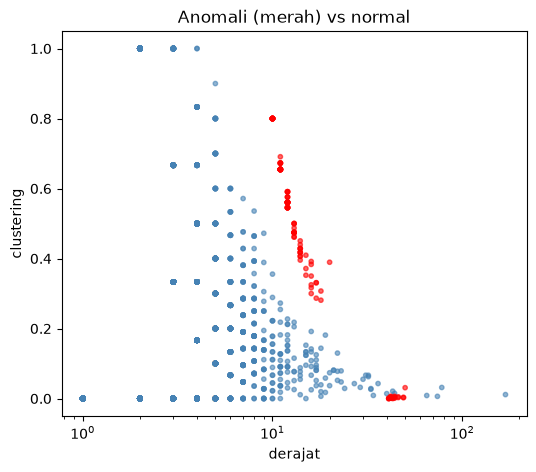

In [8]:
truth = []
for node in all_nodes:
    if node in anomalies:
        truth.append(1)
    else:
        truth.append(0)
truth = np.array(truth)
print("AUC:", round(roc_auc_score(truth, scores), 4))
print("AP :", round(average_precision_score(truth, scores), 4))

top_rows = np.argsort(-scores)[:len(anomalies)]      # simpul dengan skor tertinggi
print("dari", len(anomalies), "skor tertinggi,", truth[top_rows].sum(), "benar-benar anomali")

colors = []
for value in truth:
    if value == 1:
        colors.append("red")
    else:
        colors.append("steelblue")
fig, ax = plt.subplots(figsize=(6, 5))
ax.scatter(features["degree"], features["clustering"], c=colors, s=10, alpha=0.6)
ax.set_xscale("log")
ax.set_xlabel("derajat")
ax.set_ylabel("clustering")
ax.set_title("Anomali (merah) vs normal")
fig.savefig("fitur_anomali.png", dpi=100, bbox_inches="tight")
plt.show()